# EN3160 ASSIGNMENT 02
## FITTING AND ALIGNMENT
**M.R.A.Hakam**  **230224V**

[github.com/hakammra](https://github.com/hakammra)

### QUESTION 1  BLOB DETECTION
The LoG kernel follows the supplied blob notebook. The sunflower image is reduced to 360 by 360 pixels. Sigma values are 1 to 12 with step 0.5 and the circle radius is sqrt(2) times sigma

Positive responses find dark flower centres. Local maxima are compared across image position and scale. A response limit of 0.22, a yellow ring check of at least 35% and duplicate removal give the final circles. Boundary scales and clipped circles are excluded

In [1]:
import json
from pathlib import Path
import cv2 as cv
import numpy as np
from scipy.ndimage import maximum_filter
from IPython.display import Image, display
from q1_blobs import normalized_log_kernel
ROOT = Path.cwd()
image_path = ROOT / "images/the_berry_farms_sunflower_field.jpeg"
image = cv.imread(str(image_path), cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255
responses = np.stack([cv.filter2D(gray, cv.CV_32F, normalized_log_kernel(s))
                      for s in np.arange(1, 12.5, 0.5)], axis=2)
peaks = (responses == maximum_filter(responses, size=3)) & (responses >= 0.22)


Circle     x     y    Radius    Sigma
     1   282   338     10.61      7.5
     2   106   255      8.49        6
     3   179   327      8.49        6
     4   178   261      7.78      5.5
     5   161   290      6.36      4.5


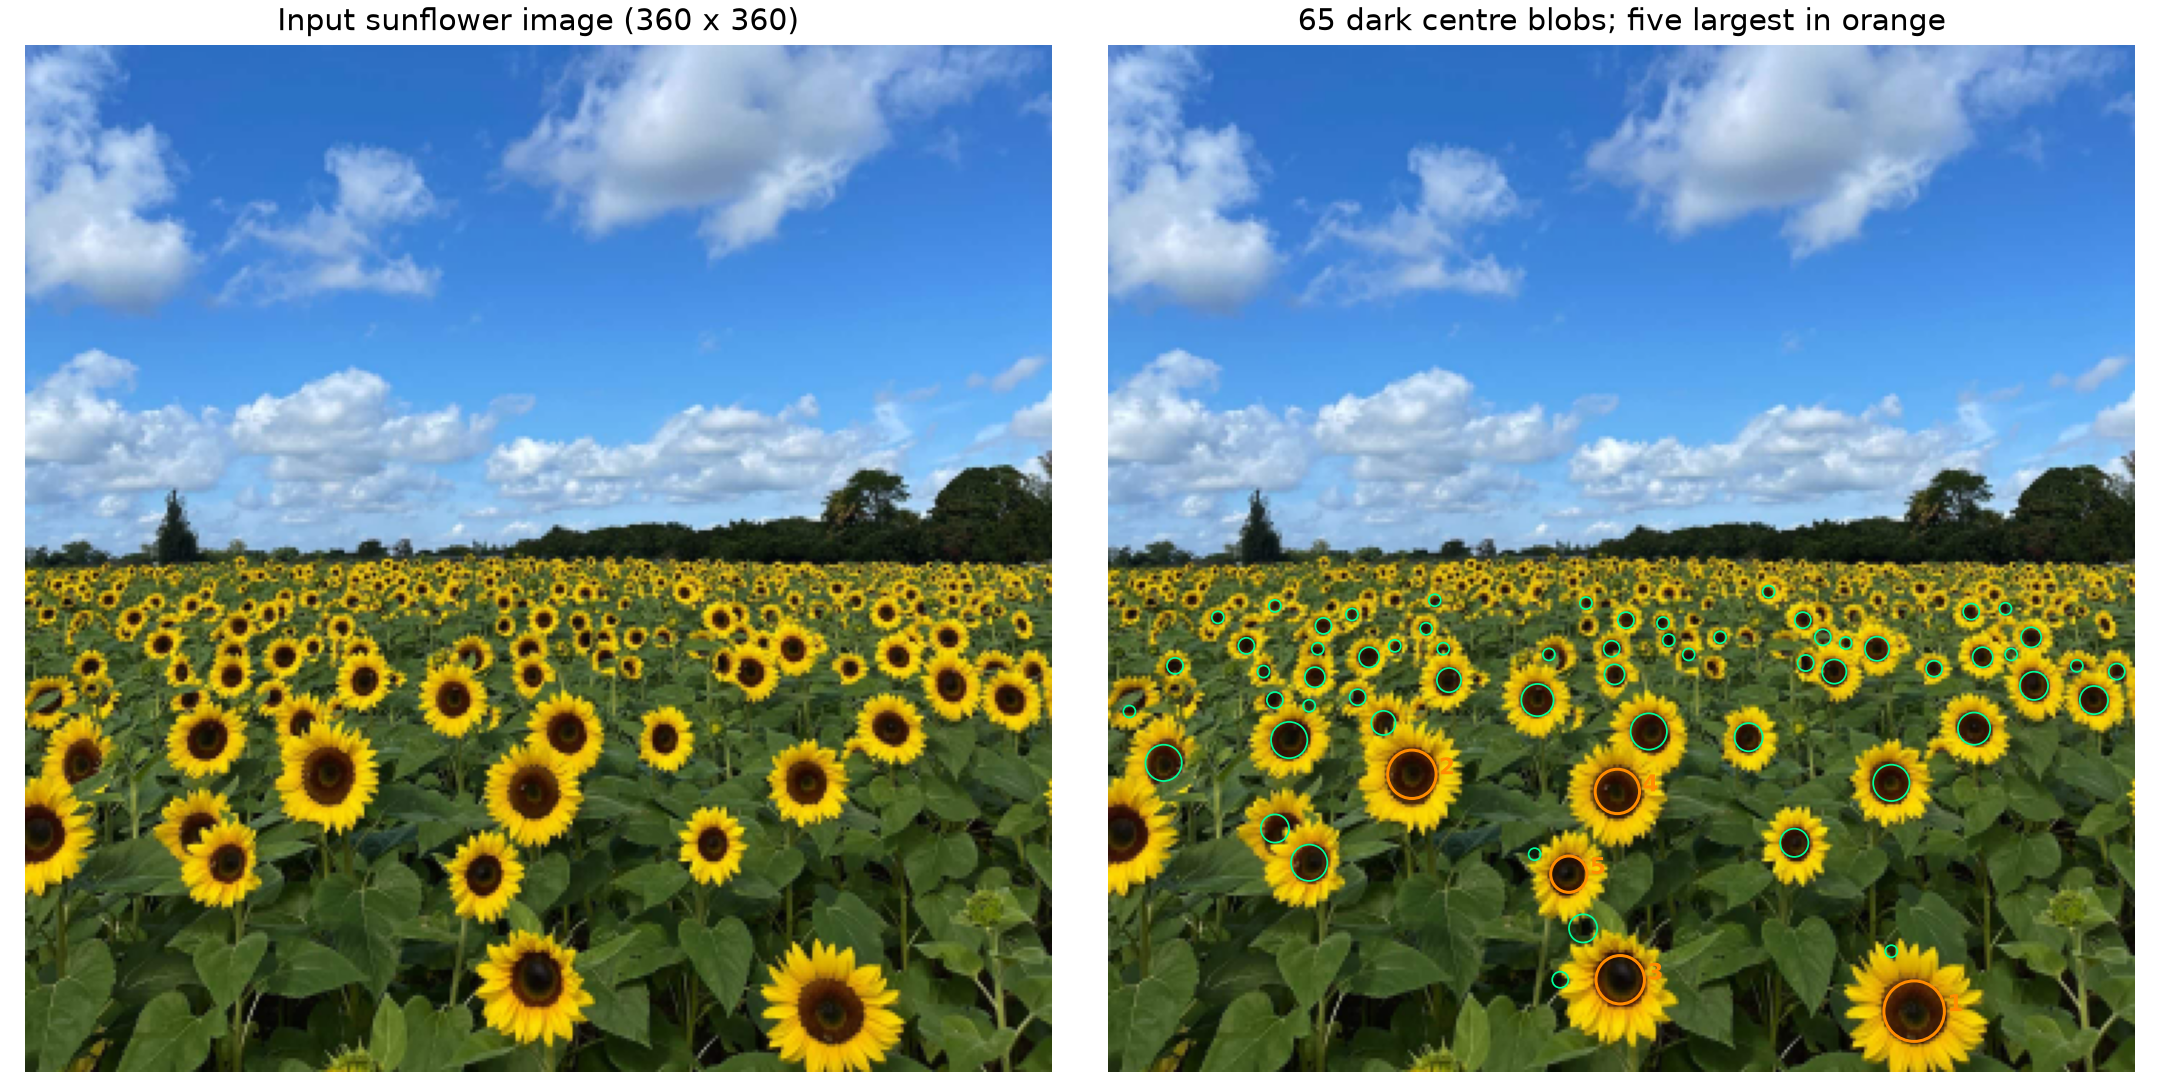

In [2]:
sunflower = json.loads((ROOT / "results/q1/sunflower_circles.json").read_text())
print("Circle     x     y    Radius    Sigma")
for i, c in enumerate(sunflower["largest_circles"], 1):
    print(f"{i:6d} {c['x']:5d} {c['y']:5d} {c['radius']:9.2f} {c['sigma']:8g}")
display(Image(filename=str(ROOT / "results/q1/sunflower_detection.png"), width=900))


There are 65 detected centres and the five largest are marked in orange. Coordinates and radii use the reduced image. The circles describe dark centres and exclude the petals

Clear foreground centres are found well, while some small distant flowers are missed. Nearby centres can merge during duplicate removal

### QUESTION 2  LINE AND CIRCLE FITTING
The supplied point generator gives 50 noisy line points and 50 noisy circle points using seed 0. The line method follows the supplied fitting notebook. Both RANSAC loops are implemented in q2_fitting.py

Two points form a line sample and three points form a circle sample. The line uses perpendicular distance with a unit normal. Its threshold is 1.4 and minimum consensus is 40. The circle uses radial distance with threshold 1.25 and minimum consensus 30. Both use 500 samples

The thresholds are about twice the expected line and radial noise levels of 0.71 and 0.625. The larger consensus wins, with mean squared error breaking ties. The line is refined by total least squares and the circle by minimizing squared radial errors

Line (a, b, d): [0.721  0.693  1.5724]
Circle (x, y, radius): [1.8982 3.0101 9.8314]
Order                 Line inliers    Circle inliers
Line then circle                54                44
Circle then line                41                57


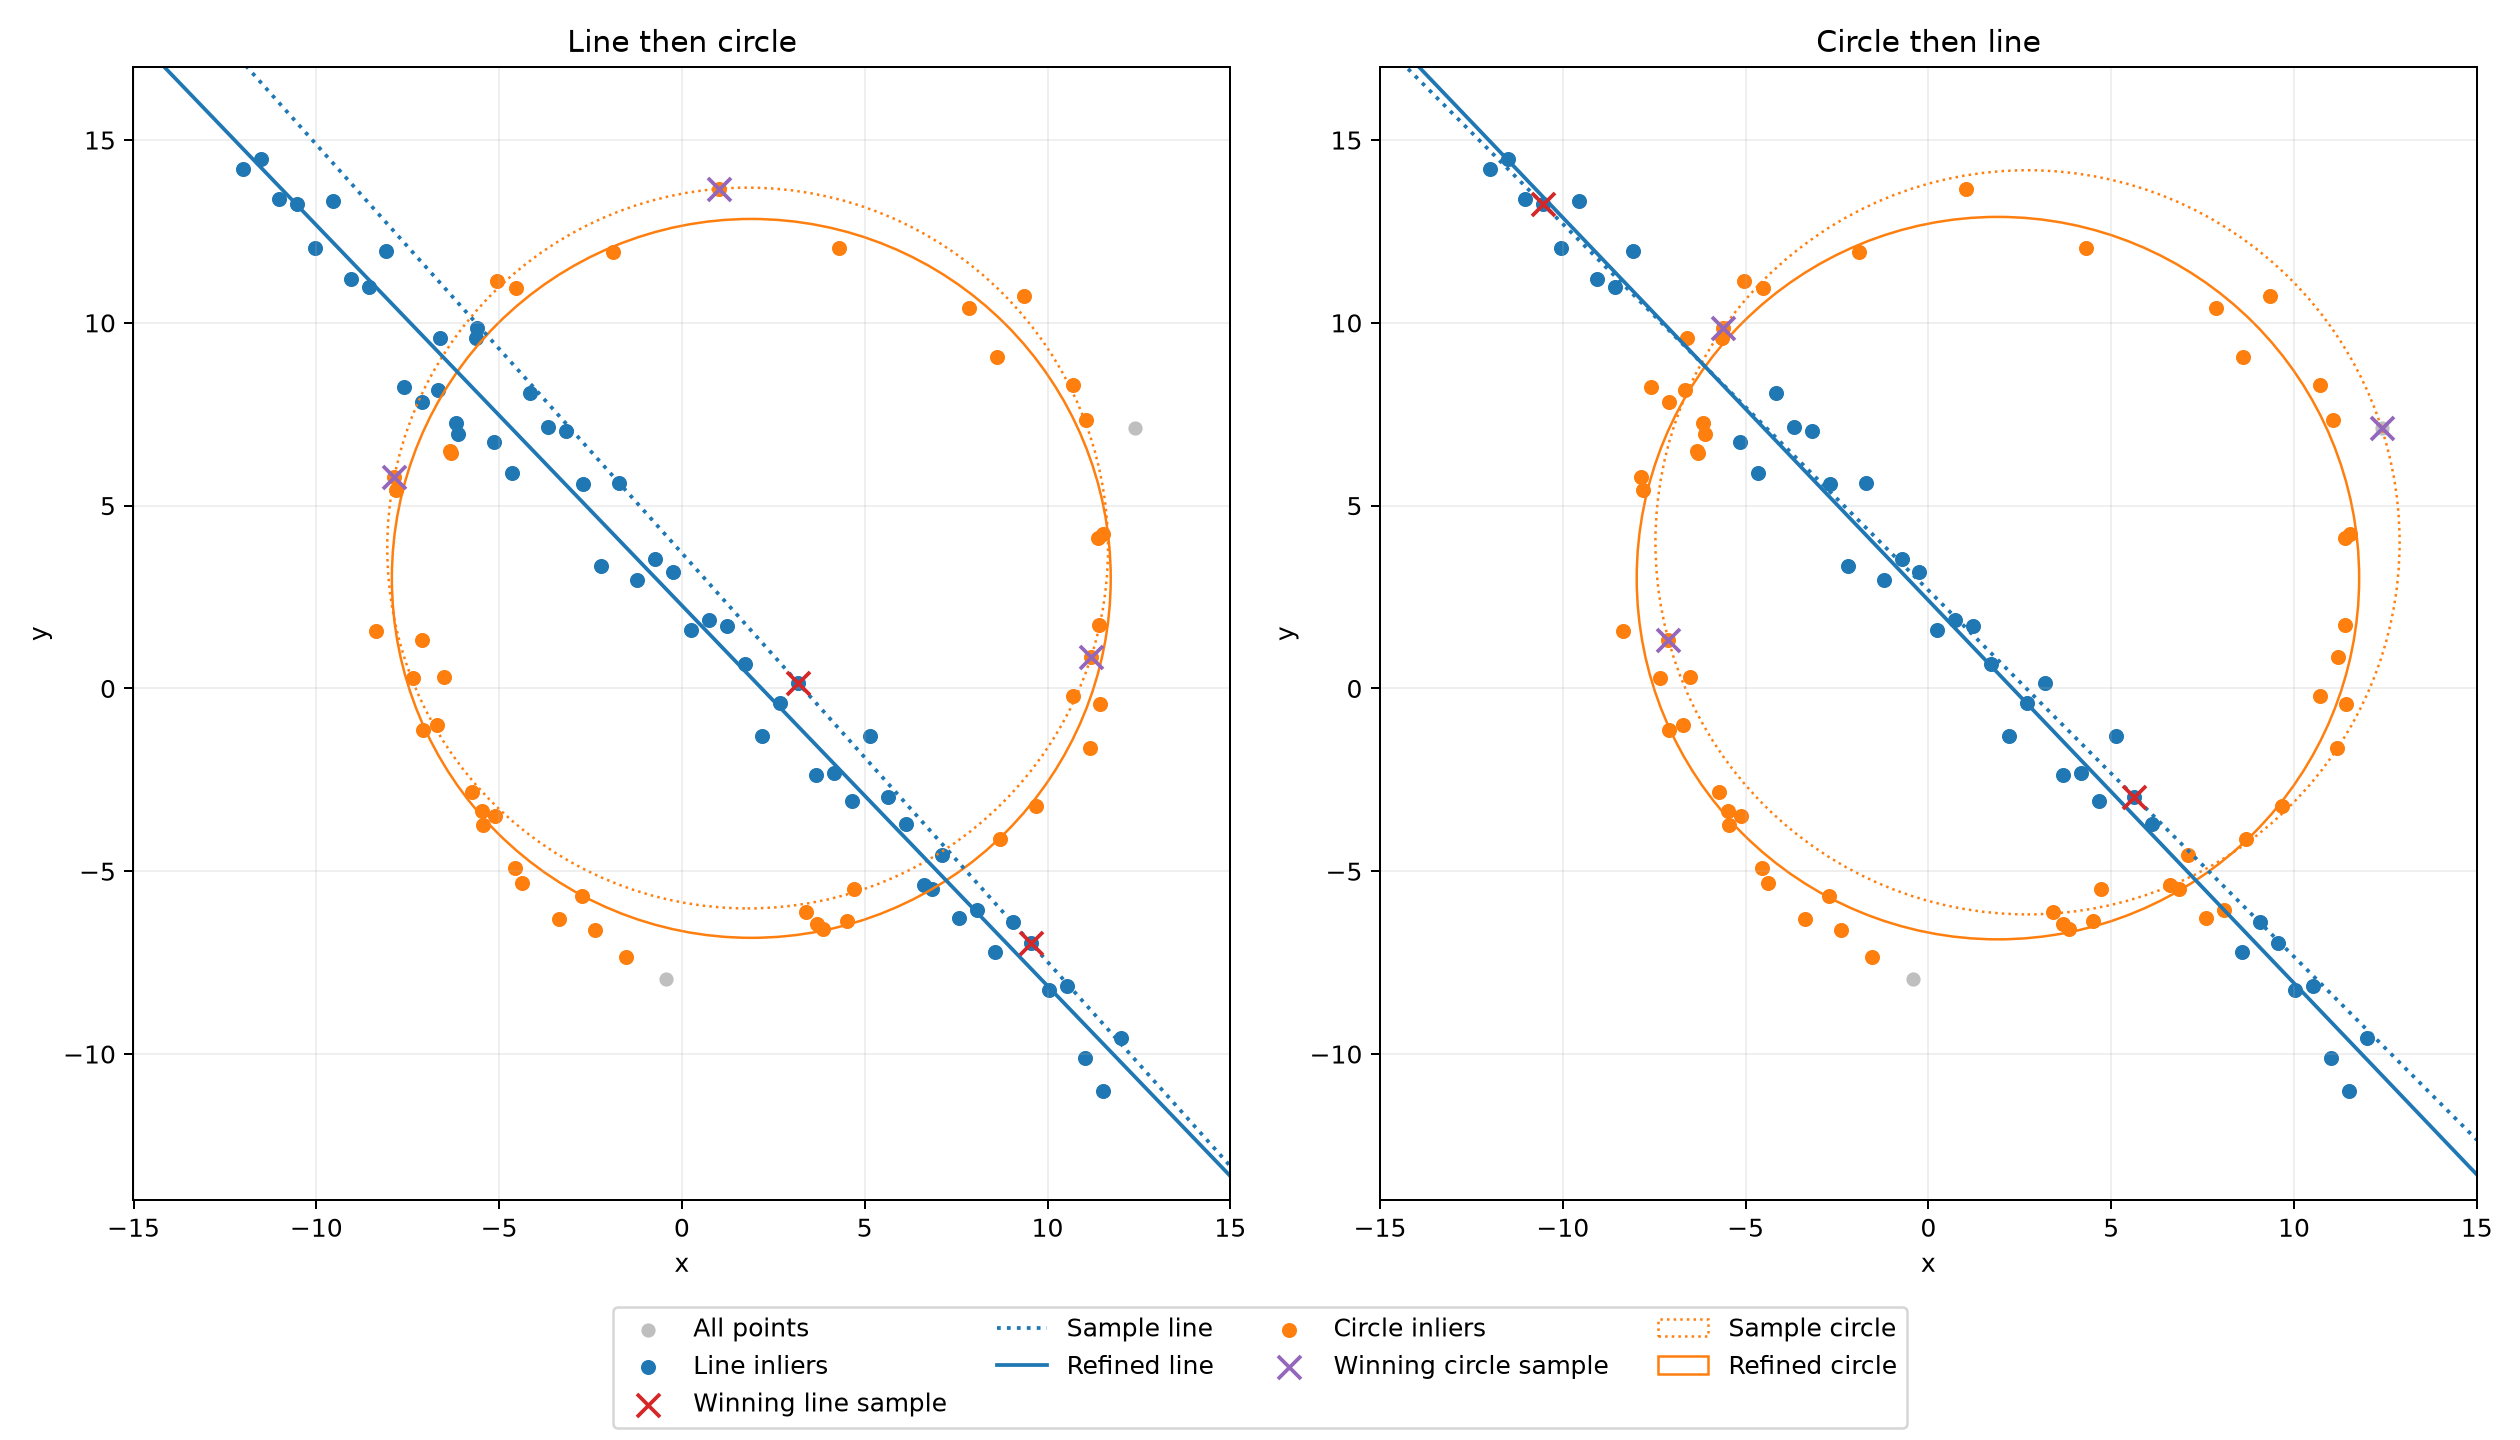

In [3]:
from q2_fitting import generate_points, ransac_line, ransac_circle, fit_circle_then_line
points = generate_points(seed=0)
line = ransac_line(points)
remaining = np.setdiff1d(np.arange(len(points)), line["inlier_indices"])
circle = ransac_circle(points[remaining])
reverse = fit_circle_then_line(points)
print("Line (a, b, d):", np.round(line["model"], 4))
print("Circle (x, y, radius):", np.round(circle["model"], 4))
print("Order                 Line inliers    Circle inliers")
print(f"Line then circle      {line['inlier_count']:12d}    {circle['inlier_count']:14d}")
print(f"Circle then line      {reverse['line']['inlier_count']:12d}    {reverse['circle']['inlier_count']:14d}")
display(Image(filename=str(ROOT / "results/q2/fitting_order_comparison.png"), width=950))


With the line fitted first, all 50 generated line points and four nearby circle points enter its consensus. Removing this consensus leaves 46 points and the circle keeps 44. The estimated centre is (1.90, 3.01) and radius is 9.83, close to the true centre (2, 3) and radius 10

Fitting the circle first keeps 57 points, including nine generated line points near its boundary. The line then keeps 41 of the 43 remaining points. Both orders work for this sample, but the first fit changes the data available to the second fit and can leave too few points for it in other samples

### QUESTION 3  FOUR POINT IMAGE COMPOSITING
Four points on a flat surface are selected in the order top left, top right, bottom right and bottom left. A homography maps the overlay corners to these points. The select option in q3_compositing.py allows the points to be clicked again

The chosen pairs place a fruit image on a box and a butterfly image on a wall. These are OpenCV sample images, with source details saved beside them. Opacity is 0.8 for the box and 0.85 for the wall. The saved coordinates reproduce both results

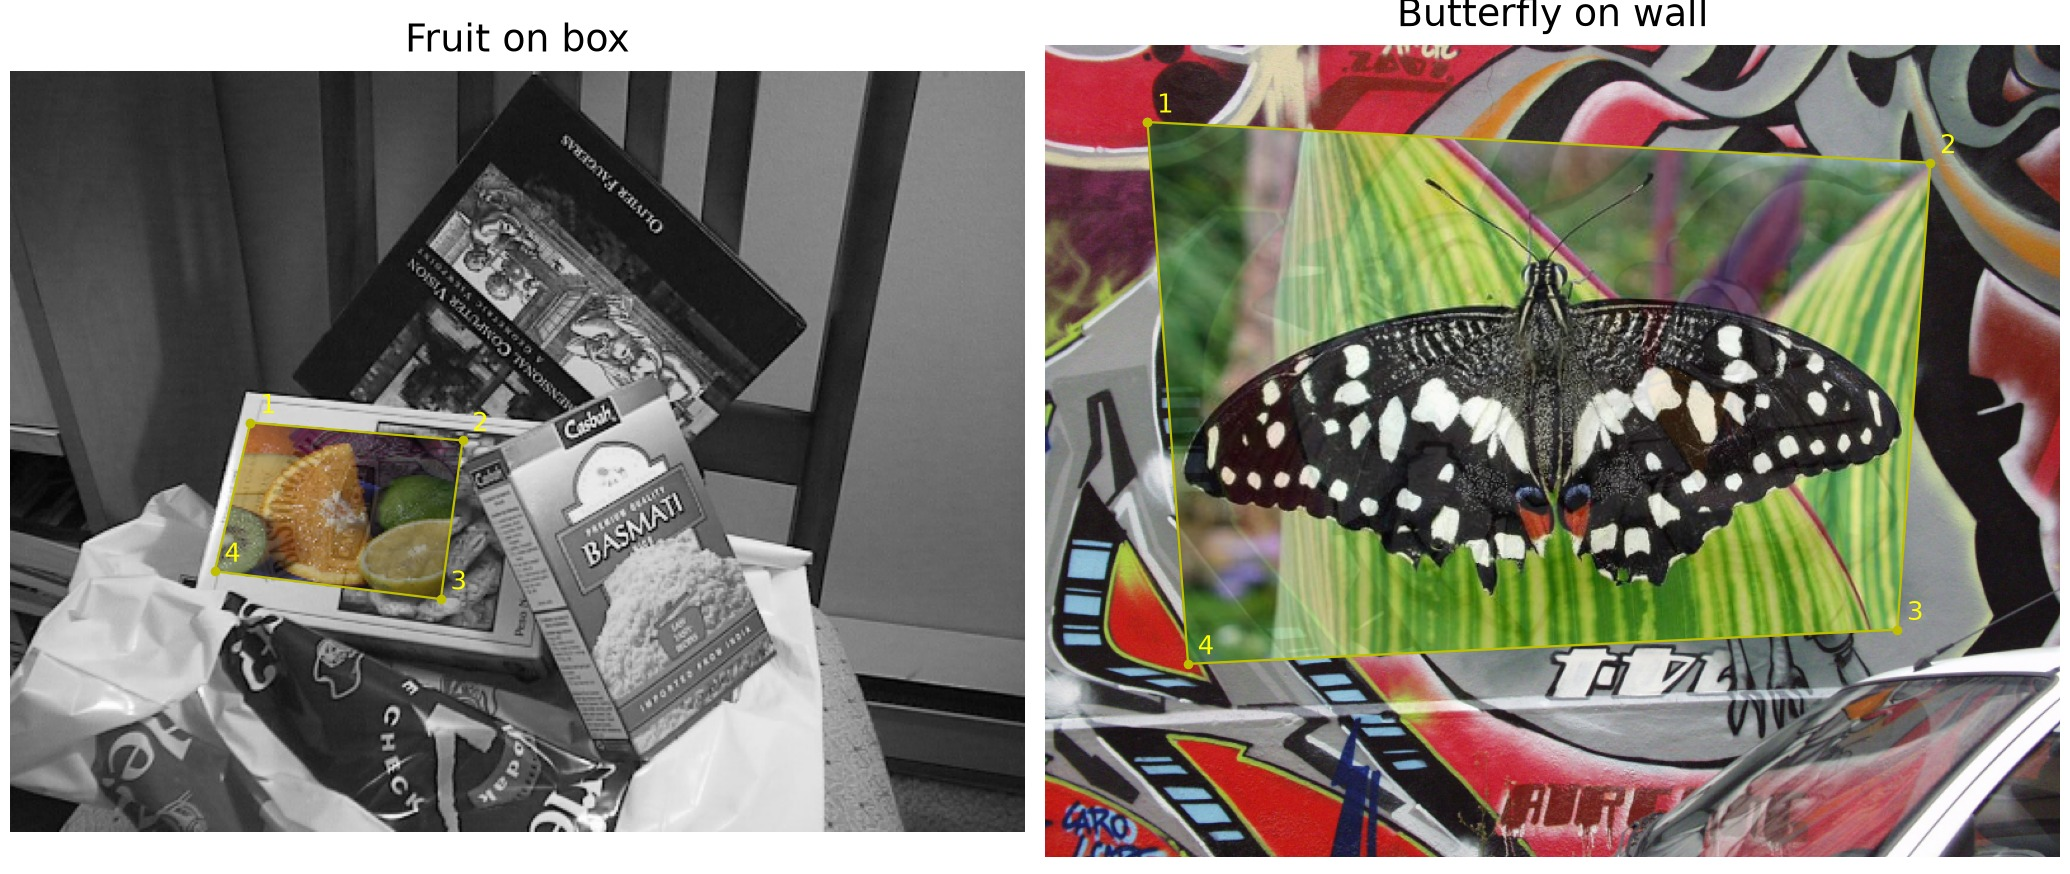

In [4]:
from q3_compositing import composite_overlay
for name in ["box", "wall"]:
    selection = json.loads((ROOT / f"results/q3/{name}_points.json").read_text())
    background = cv.imread(str(ROOT / selection["background"]))
    overlay = cv.imread(str(ROOT / selection["overlay"]), cv.IMREAD_UNCHANGED)
    composite, H, mask = composite_overlay(background, overlay, selection["corners"], selection["opacity"])
display(Image(filename=str(ROOT / "results/report/composites.jpg"), width=950))


Both overlays follow the selected surface. Blending keeps some surface texture visible and changes only pixels inside the warped overlay mask

### QUESTION 4  PCB ALIGNMENT
SIFT and the ratio test follow the supplied blob example, using BFMatcher with L2 distance as required. A ratio limit of 0.8 and mutual matches reject ambiguous pairs. RANSAC estimates each homography with a five pixel threshold

Features are detected with the longer side reduced to 1000 pixels and are mapped back to the original coordinates. Each view below shows up to 80 inlier matches to AECC1

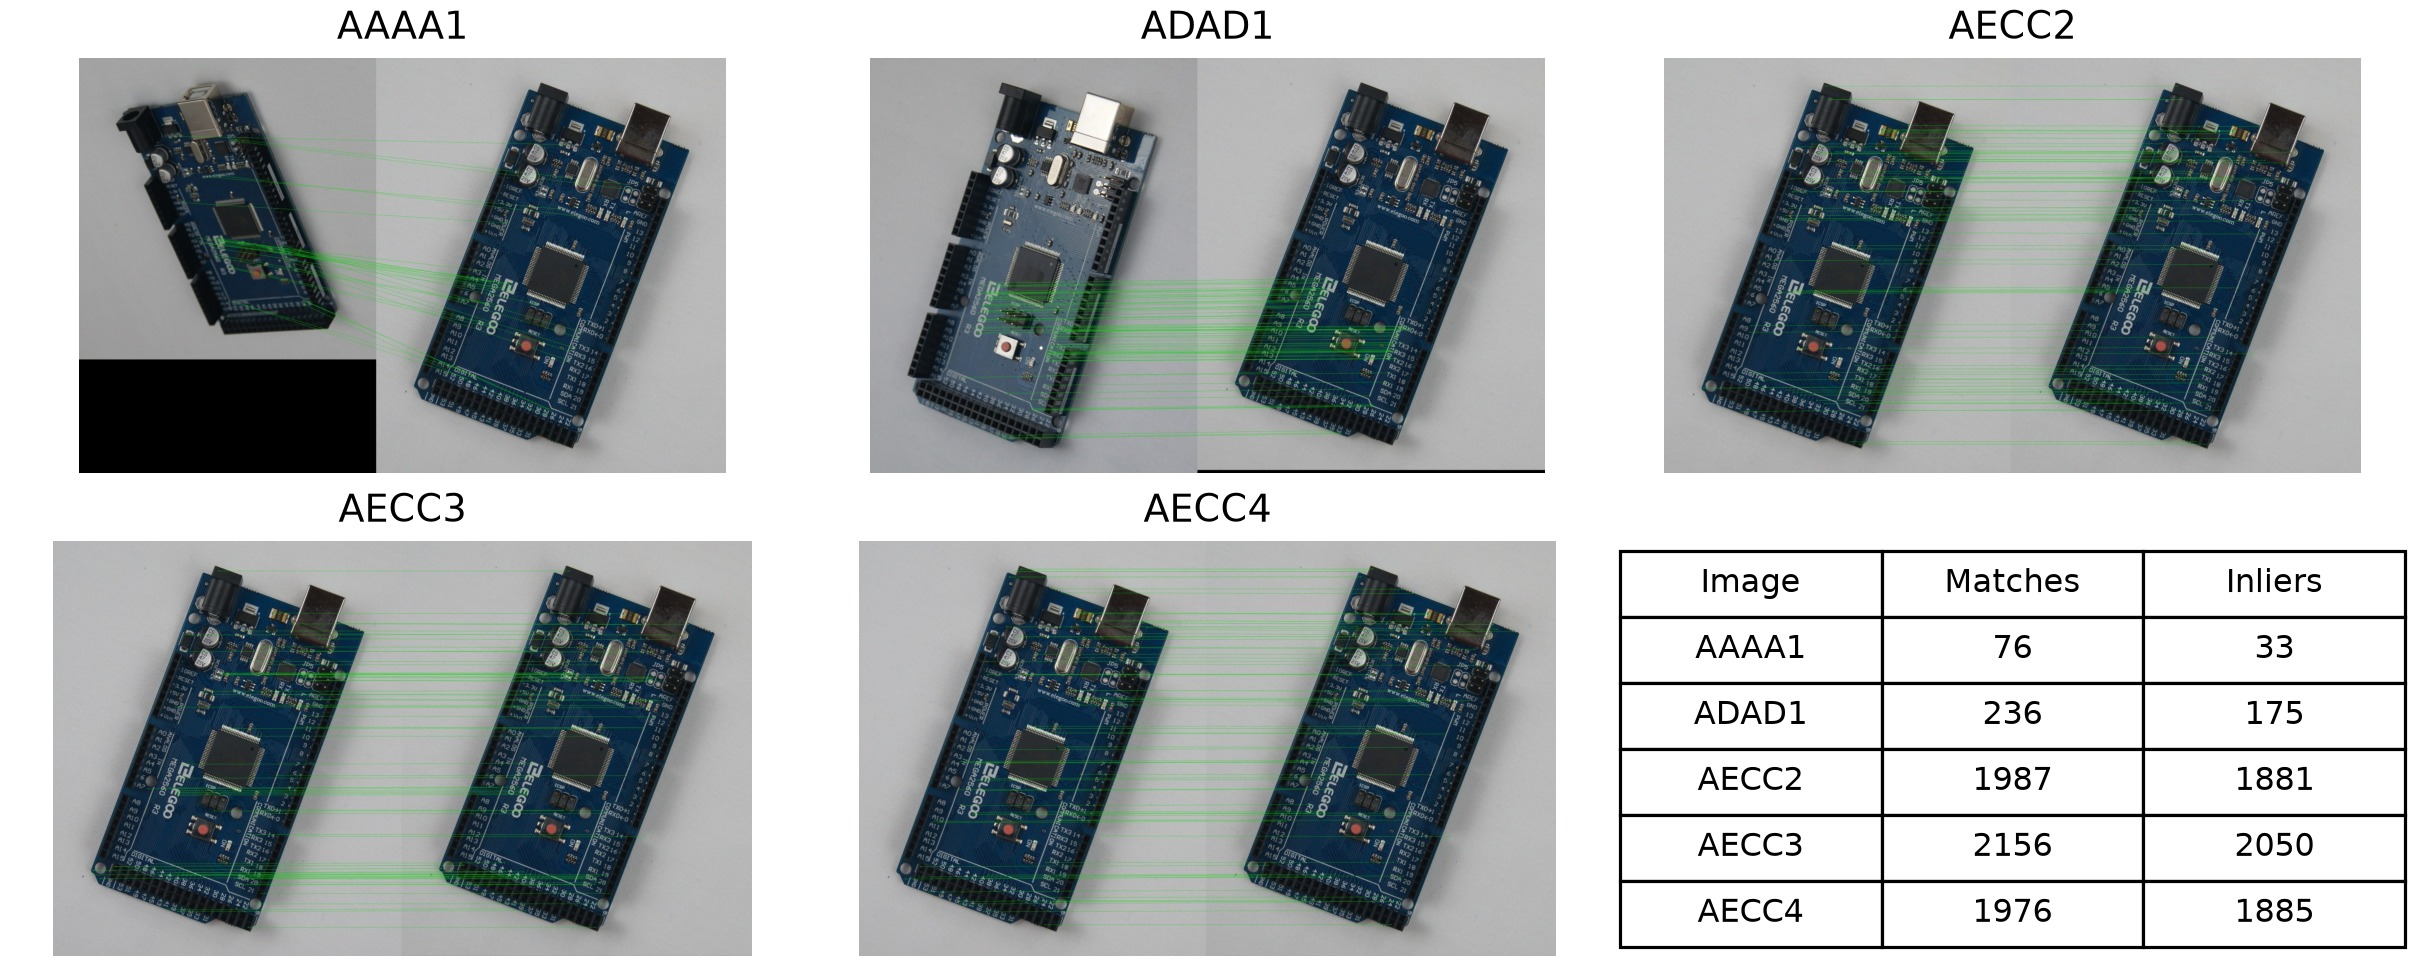

In [5]:
display(Image(filename=str(ROOT / "results/report/pcb_matches.jpg"), width=1000))


### QUESTION 4  PCB ALIGNMENT CONTINUED
Each image is warped into the original AECC1 size. The absolute grayscale difference is measured from 0 to 255. A warped image of ones identifies valid coverage and empty borders are excluded

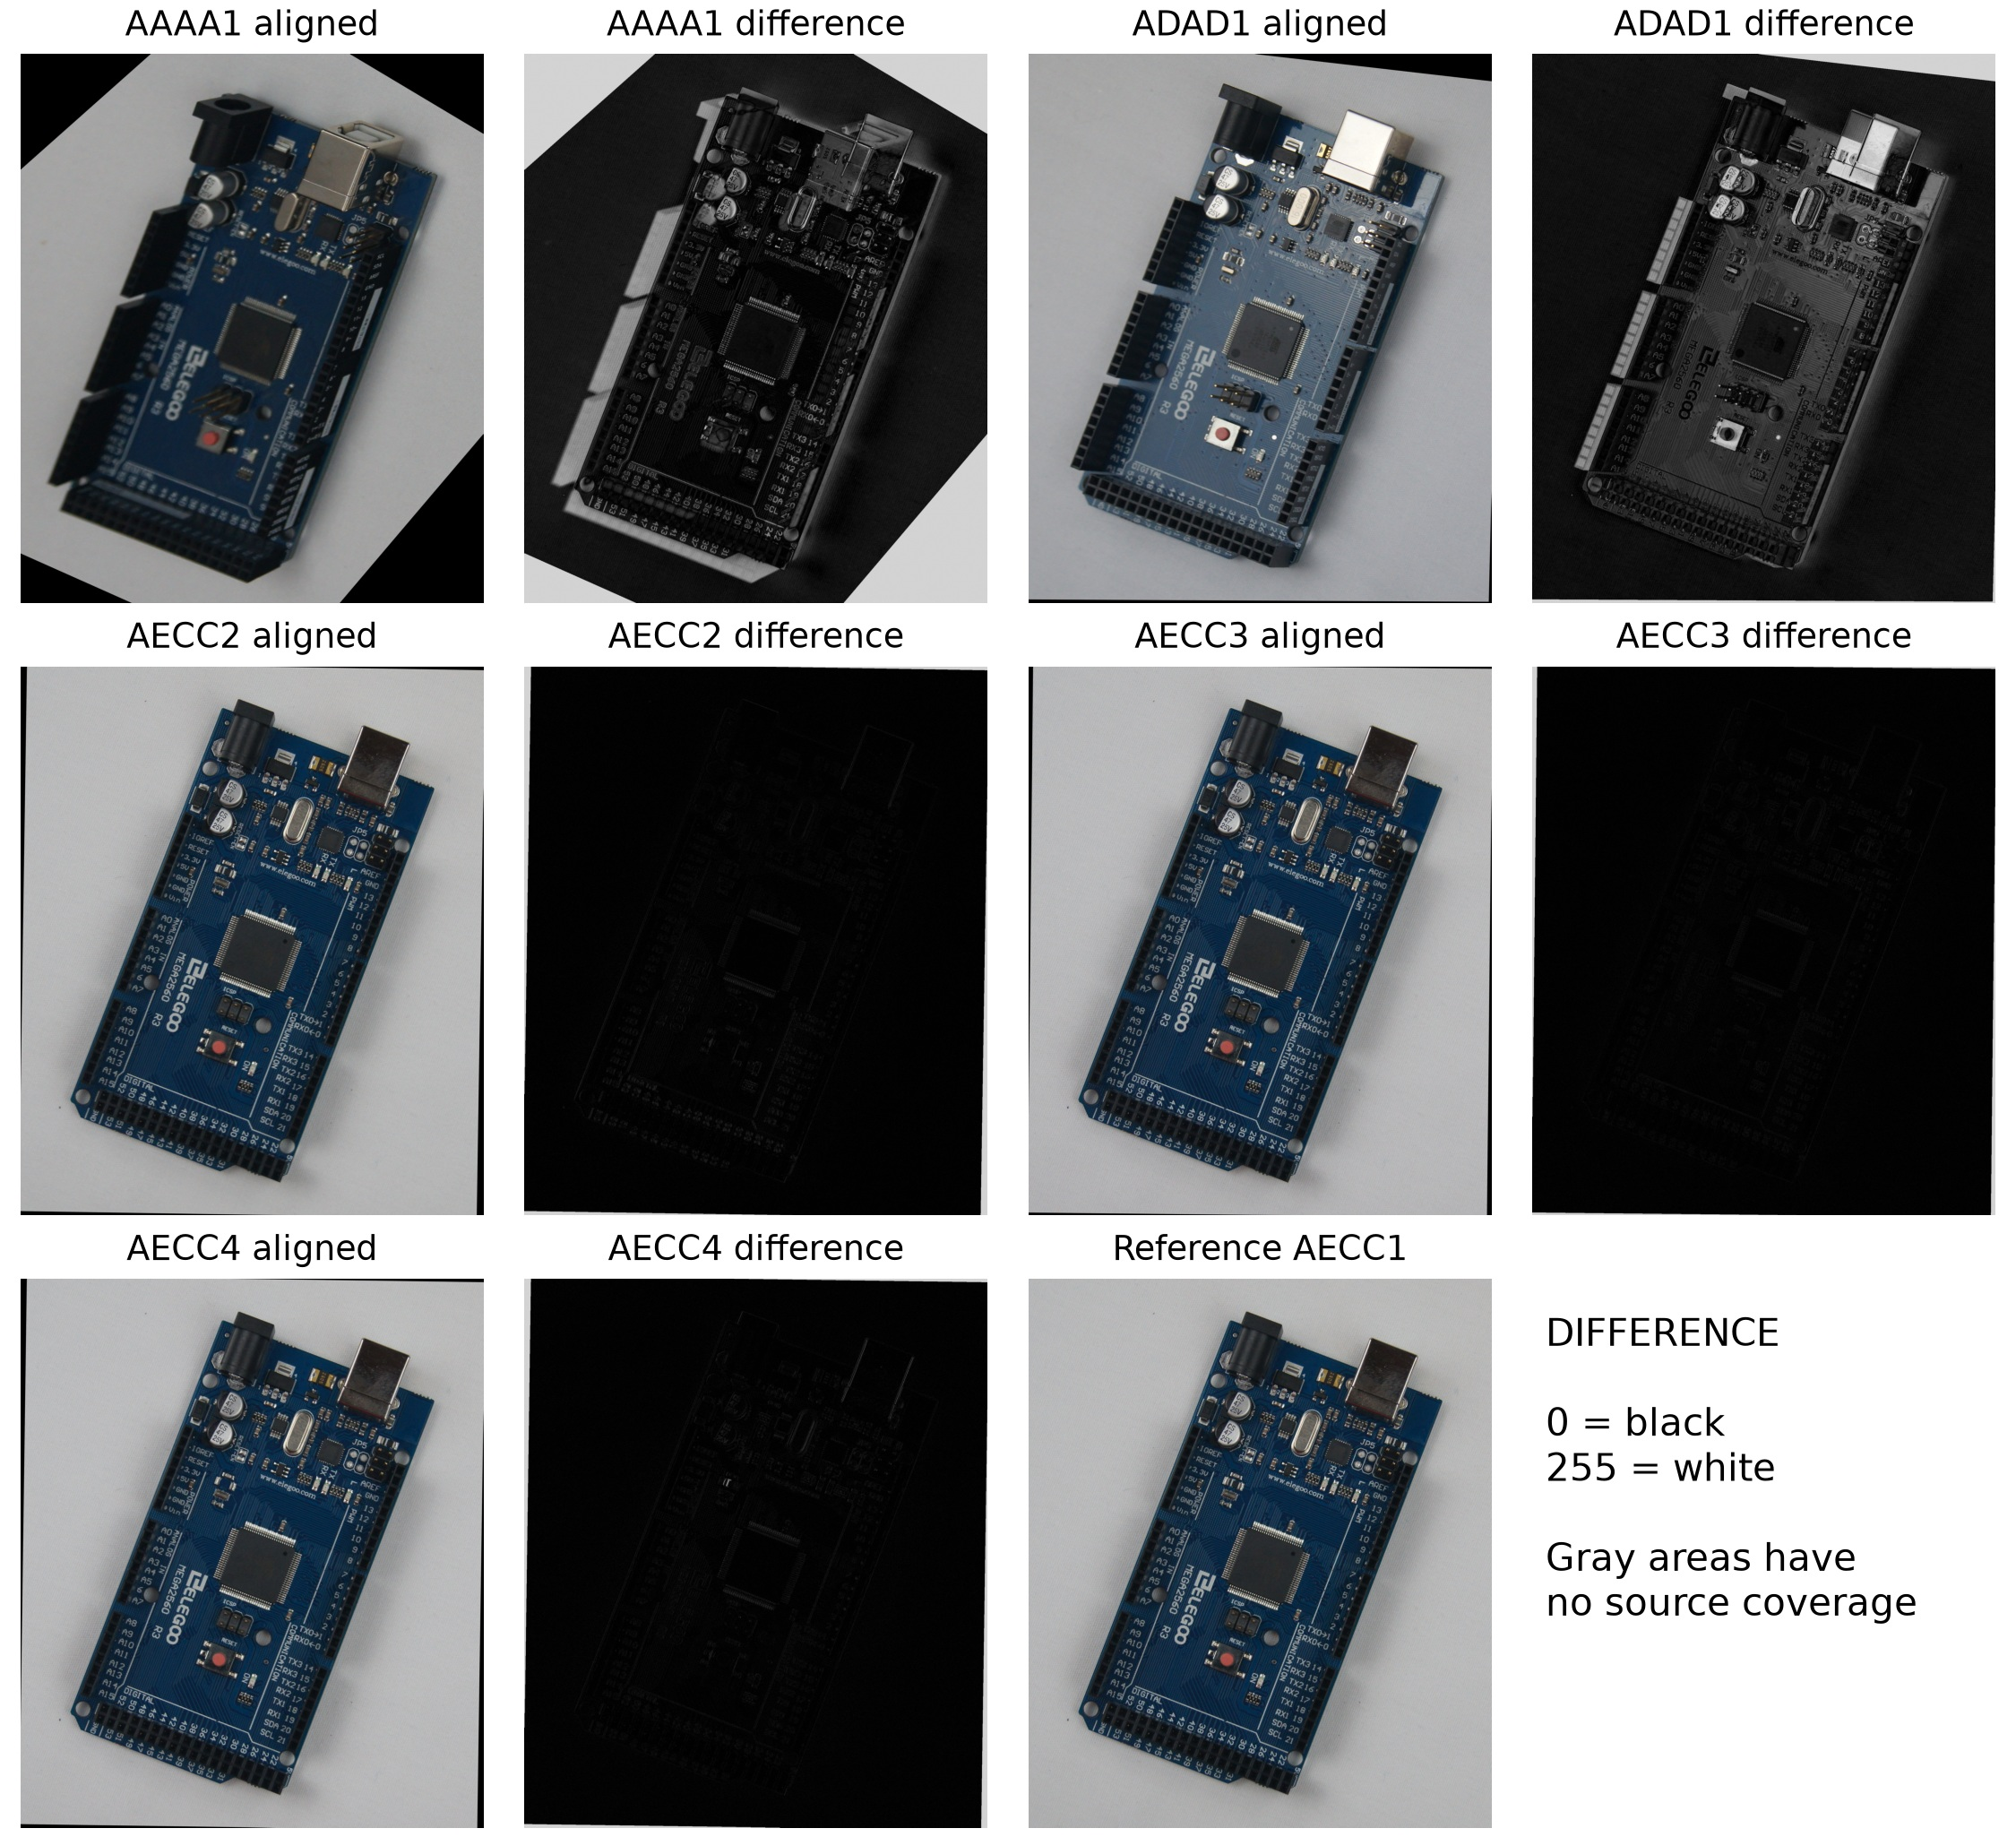

In [6]:
from q4_alignment import PCB_NAMES, warp_and_difference
reference = cv.imread(str(ROOT / "images/pcbs/AECC1.jpg"))
for name in PCB_NAMES:
    stem = Path(name).stem
    record = json.loads((ROOT / f"results/q4/{stem}_homography.json").read_text())
    source = cv.imread(str(ROOT / "images/pcbs" / name))
    aligned, difference, valid = warp_and_difference(source, reference, record["homography"])
display(Image(filename=str(ROOT / "results/report/pcb_differences.jpg"), width=1000))


The AECC2, AECC3 and AECC4 differences are mostly dark, showing brightness values close to the reference. AAAA1 and ADAD1 have stronger changes around component edges and reflective areas

The USB Type B port, capacitors and reset button stand above the board. A homography aligns one plane, so these raised parts can still shift between views. This is parallax. Reflections, shadows, lighting changes and small alignment errors also contribute to the differences